<a href="https://colab.research.google.com/github/namgiju/mlprog/blob/main/9%EC%A3%BC%EC%B0%A8/samsung_rnn_cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. 필요한 라이브러리 설치 및 불러오기

In [1]:
%pip install -q finance-datareader


In [2]:
import FinanceDataReader as fdr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


## 2. 삼성전자 데이터 불러오기

In [3]:
samsung = fdr.DataReader('005930', '2016')
print(samsung)


              Open    High     Low   Close    Volume    Change
Date                                                          
2016-01-04   25200   25200   24100   24100    306939 -0.043651
2016-01-05   24040   24360   23720   24160    216002  0.002490
2016-01-06   24160   24160   23360   23500    366752 -0.027318
2016-01-07   23320   23660   23020   23260    282388 -0.010213
2016-01-08   23260   23720   23260   23420    257763  0.006879
...            ...     ...     ...     ...       ...       ...
2026-11-03  220500  223000  217000  222000  13391670 -0.034783
2026-11-04  226500  228000  208000  221500  22248738 -0.002252
2026-11-05  213000  213500  199800  201500  24657743 -0.090293
2026-11-06  180000  196500  179200  193500  35516270 -0.039702
2026-11-09  187200  195000  187000  193800   8989228  0.001550

[2660 rows x 6 columns]


In [4]:
openValues = samsung[['Open']]


## 3. 특징값 정규화

In [5]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0, 1))
scaled = scaler.fit_transform(openValues)


## 4. 훈련 데이터와 테스트 데이터 분리

In [6]:
TEST_SIZE = 200
train_data = scaled[:-TEST_SIZE]
test_data = scaled[-TEST_SIZE:]


## 5. 순차 훈련 데이터 생성

이전 30개 거래일의 시가로 다음 거래일의 시가를 예측합니다. 사진의 설명에는 60개라고 쓰여 있지만 실제 코드의 30을 따릅니다.

In [7]:
def make_sample(data, window):
    train = []
    target = []
    for i in range(len(data) - window):
        train.append(data[i:i + window])
        target.append(data[i + window])
    return np.array(train), np.array(target)

X_train, y_train = make_sample(train_data, 30)


## 6. SimpleRNN 모델 구축

In [8]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import SimpleRNN

model = Sequential()
model.add(SimpleRNN(16,
               input_shape=(X_train.shape[1], 1),
               activation='tanh',
               return_sequences=False))
model.add(Dense(1))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


## 7. 모델 학습

100 epochs를 실행하므로 시간이 걸릴 수 있습니다.

In [9]:
model.compile(optimizer='adam', loss='mean_squared_error')
model.fit(X_train, y_train, epochs=100, batch_size=16)


Epoch 1/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - loss: 0.0010
Epoch 2/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 2.6859e-04
Epoch 3/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.7818e-04
Epoch 4/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 1.3124e-04
Epoch 5/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 1.1114e-04
Epoch 6/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 9.5827e-05
Epoch 7/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 8.3006e-05
Epoch 8/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 7.3079e-05
Epoch 9/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 6.6955e-05
Epoch 10/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 6.1311e-05
Epoch 11/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.6229e-05
Epoch 12/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.3553e-05
Epoch 13/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.9697e-05
Epoch 14/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4

## 8. 테스트 데이터 예측

In [10]:
X_test, y_test = make_sample(test_data, 30)
pred = model.predict(X_test)


6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 80ms/step


## 9. 실제값과 예측값 비교 그래프

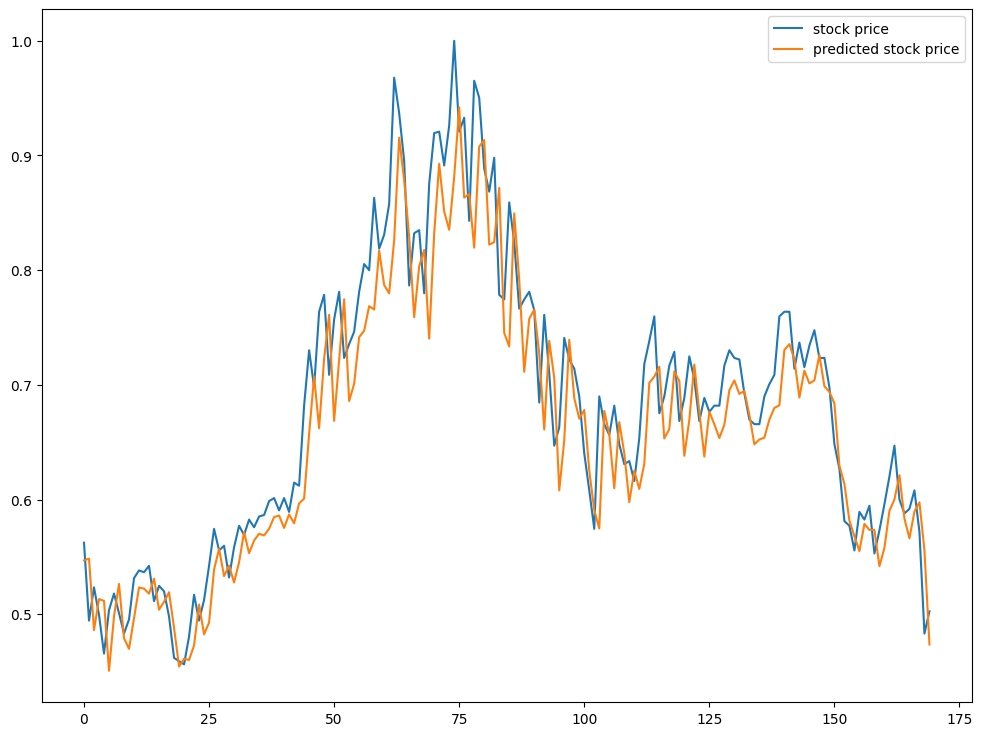

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 9))
plt.plot(y_test, label='stock price')
plt.plot(pred, label='predicted stock price')
plt.legend()
plt.show()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 30, 16)         │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 15, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 240)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │         3,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,937 (15.38 KB)

 Trainable params: 3,937 (15.38 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
152/152 - 6s - 39ms/step - loss: 4.1340e-04
Epoch 2/100
152/152 - 0s - 3ms/step - loss: 8.9261e-05
Epoch 3/100
152/152 - 0s - 3ms/step - loss: 8.3148e-05
Epoch 4/100
152/152 - 0s - 3ms/step - loss: 7.0551e-05
Epoch 5/100
152/152 - 0s - 3ms/step - loss: 6.2127e-05
Epoch 6/100
152/152 - 0s - 2ms/step - loss: 5.6875e-05
Epoch 7/100
152/152 - 0s - 3ms/step - loss: 5.0047e-05
Epoch 8/100
152/152 - 0s - 3ms/step - loss: 4.5372e-05
Epoch 9/100
152/152 - 0s - 3ms/step - loss: 4.5288e-05
Epoch 10/100
152/152 - 0s - 3ms/step - loss: 4.3257e-05
Epoch 11/100
152/152 - 0s - 3ms/step - loss: 4.3106e-05
Epoch 12/100
152/152 - 0s - 2ms/step - loss: 3.7035e-05
Epoch 13/100
152/152 - 0s - 3ms/step - loss: 3.7168e-05
Epoch 14/100
152/152 - 0s - 2ms/step - loss: 3.5070e-05
Epoch 15/100
152/152 - 0s - 2ms/step - loss: 3.4394e-05
Epoch 16/100
152/152 - 1s - 4ms/step - loss: 3.6158e-05
Epoch 17/100
152/152 - 0s - 2ms/step - loss: 3.3104e-05
Epoch 18/100
152/152 - 0s - 3ms/step - loss: 3.1314e-05


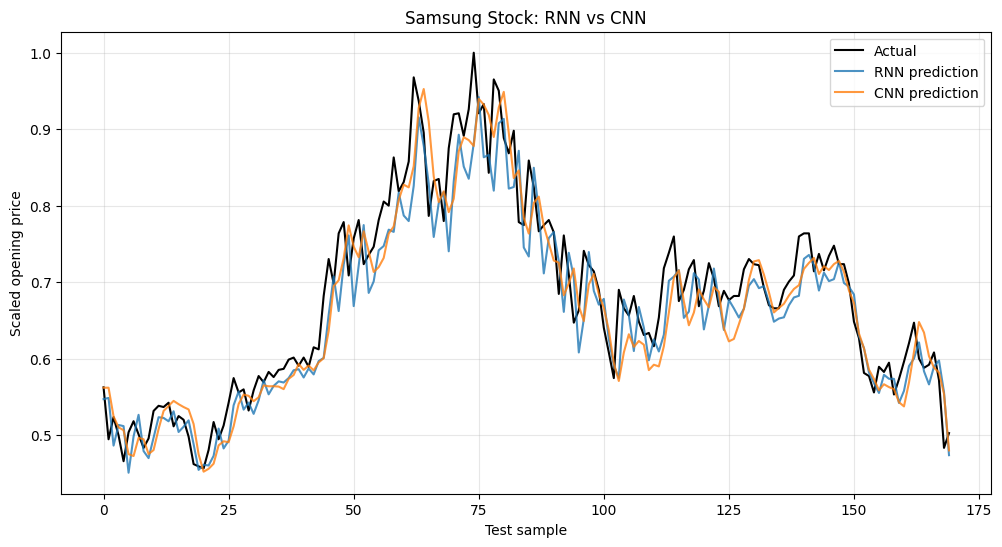

In [12]:
# 10. 1차원 CNN으로 주가 예측하기 (앞의 RNN 셀 실행 후 실행)
# 같은 X_train, y_train, X_test, y_test로 비교합니다.
from tensorflow.keras import Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense

cnn_model = Sequential([
    Input(shape=(X_train.shape[1], X_train.shape[2])),
    Conv1D(filters=16, kernel_size=3, padding='same', activation='relu'),
    MaxPooling1D(pool_size=2, padding='same'),
    Flatten(),
    Dense(16, activation='relu'),
    Dense(1)
])
cnn_model.compile(optimizer='adam', loss='mean_squared_error')
cnn_model.summary()

# RNN과 동일하게 100 epochs, batch_size 16으로 학습
cnn_history = cnn_model.fit(
    X_train, y_train, epochs=100, batch_size=16, verbose=2
)

# 11. CNN 예측 및 RNN과 비교
cnn_pred = cnn_model.predict(X_test, verbose=0)
rnn_pred = model.predict(X_test, verbose=0)

print('RNN test MSE:', np.mean((y_test - rnn_pred) ** 2))
print('CNN test MSE:', np.mean((y_test - cnn_pred) ** 2))

plt.figure(figsize=(12, 6))
plt.plot(y_test, label='Actual', color='black')
plt.plot(rnn_pred, label='RNN prediction', alpha=0.8)
plt.plot(cnn_pred, label='CNN prediction', alpha=0.8)
plt.title('Samsung Stock: RNN vs CNN')
plt.xlabel('Test sample')
plt.ylabel('Scaled opening price')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 앞의 교재 전처리를 공유한 비교입니다.
# 전체 데이터로 정규화했으므로 엄밀한 테스트 평가에는
# 학습 데이터에만 scaler를 fit하는 전처리가 필요합니다.
